# Tugas Praktikum 5: Sequential Pattern Analysis
Dataset: Online Retail (UCI Machine Learning Repository), berisi transaksi ritel online sebuah toko di Inggris periode Desember 2010 sampai Desember 2011, meliputi nomor invoice, kode dan deskripsi produk, jumlah, harga, ID pelanggan, serta negara.

Link: https://archive.ics.uci.edu/dataset/352/online+retail

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math, time
from collections import defaultdict, Counter

pd.set_option('display.max_colwidth', 120)
sns.set_theme(style='whitegrid')

## 1. Import Dataset

In [2]:
df = pd.read_excel('Online Retail.xlsx')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print('Shape dataset:', df.shape)

Shape dataset: (541909, 8)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## 2. Eksplorasi dan Pembersihan Data

### 2.1 Eksplorasi awal

In [6]:
print('Jumlah missing value per kolom:')
print(df.isnull().sum())
print()
print('Invoice batal (diawali C)  :', df['InvoiceNo'].astype(str).str.startswith('C').sum())
print('Quantity <= 0              :', (df['Quantity'] <= 0).sum())
print('Rentang tanggal            :', df['InvoiceDate'].min(), 's.d.', df['InvoiceDate'].max())

Jumlah missing value per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Invoice batal (diawali C)  : 9288
Quantity <= 0              : 10624
Rentang tanggal            : 2010-12-01 08:26:00 s.d. 2011-12-09 12:50:00


In [7]:
def ringkasan(data, label):
    return pd.Series({
        'Jumlah baris'    : len(data),
        'Jumlah invoice'  : data['InvoiceNo'].nunique(),
        'Jumlah pelanggan': data['CustomerID'].nunique(),
        'Jumlah produk'   : data['Description'].nunique(),
    }, name=label)

sebelum = ringkasan(df, 'Sebelum')
sebelum

Jumlah baris        541909
Jumlah invoice       25900
Jumlah pelanggan      4372
Jumlah produk         4223
Name: Sebelum, dtype: int64

### 2.2 Data cleaning

In [8]:
data = df.copy()
log = [('Data awal', len(data))]

data = data.dropna(subset=['Description'])
log.append(('Hapus Description kosong', len(data)))

data = data[~data['InvoiceNo'].astype(str).str.startswith('C')]
log.append(('Hapus invoice batal (C...)', len(data)))

data = data[data['Quantity'] > 0]
log.append(('Hapus Quantity <= 0', len(data)))

data = data.dropna(subset=['CustomerID'])
log.append(('Hapus CustomerID kosong', len(data)))

# item non-produk (berdasarkan StockCode)
non_produk = ['POST', 'DOT', 'M', 'm', 'C2', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'PADS', 'D', 'S', 'B']
print('Item non-produk yang dihapus:')
print(data.loc[data['StockCode'].astype(str).isin(non_produk), 'Description'].value_counts())
data = data[~data['StockCode'].astype(str).isin(non_produk)]
log.append(('Hapus item non-produk', len(data)))

# rapikan tipe data
data['CustomerID'] = data['CustomerID'].astype(int)
data['InvoiceNo'] = data['InvoiceNo'].astype(str)
data['Description'] = data['Description'].str.strip().str.replace(r'\s+', ' ', regex=True)  # samakan spasi ganda

log_df = pd.DataFrame(log, columns=['Tahap', 'Jumlah baris'])
log_df['Baris terhapus'] = -log_df['Jumlah baris'].diff().fillna(0).astype(int)
log_df

Item non-produk yang dihapus:
Description
POSTAGE                       1099
Manual                         290
CARRIAGE                       133
DOTCOM POSTAGE                  16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       4
Name: count, dtype: int64


,Tahap,Jumlah baris,Baris terhapus
0,Data awal,541909,0
1,Hapus Description kosong,540455,1454
2,Hapus invoice batal (C...),531167,9288
3,Hapus Quantity <= 0,530693,474
4,Hapus CustomerID kosong,397924,132769
5,Hapus item non-produk,396370,1554


In [9]:
sesudah = ringkasan(data, 'Sesudah')
perbandingan = pd.concat([sebelum, sesudah], axis=1)
perbandingan['Selisih'] = perbandingan['Sesudah'] - perbandingan['Sebelum']
perbandingan['% tersisa'] = (perbandingan['Sesudah'] / perbandingan['Sebelum'] * 100).round(1)
perbandingan

,Sebelum,Sesudah,Selisih,% tersisa
Jumlah baris,541909,396370,-145539,73.1
Jumlah invoice,25900,18405,-7495,71.1
Jumlah pelanggan,4372,4335,-37,99.2
Jumlah produk,4223,3852,-371,91.2


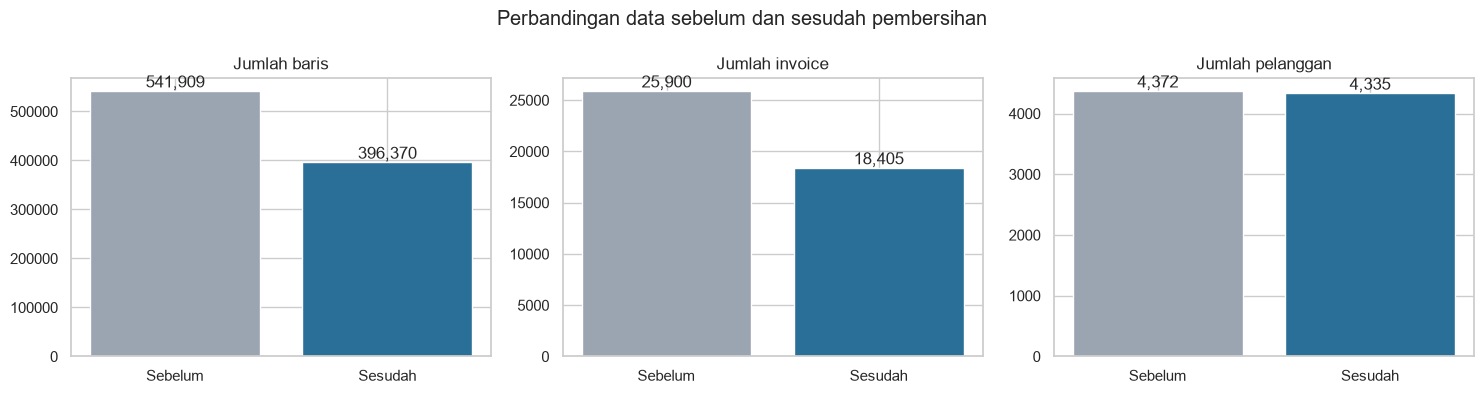

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, kolom in zip(axes, ['Jumlah baris', 'Jumlah invoice', 'Jumlah pelanggan']):
    nilai = perbandingan.loc[kolom, ['Sebelum', 'Sesudah']]
    ax.bar(nilai.index, nilai.values, color=['#9aa5b1', '#2a6f97'])
    for i, v in enumerate(nilai.values):
        ax.text(i, v, f'{int(v):,}', ha='center', va='bottom')
    ax.set_title(kolom)
plt.suptitle('Perbandingan data sebelum dan sesudah pembersihan')
plt.tight_layout()
plt.show()

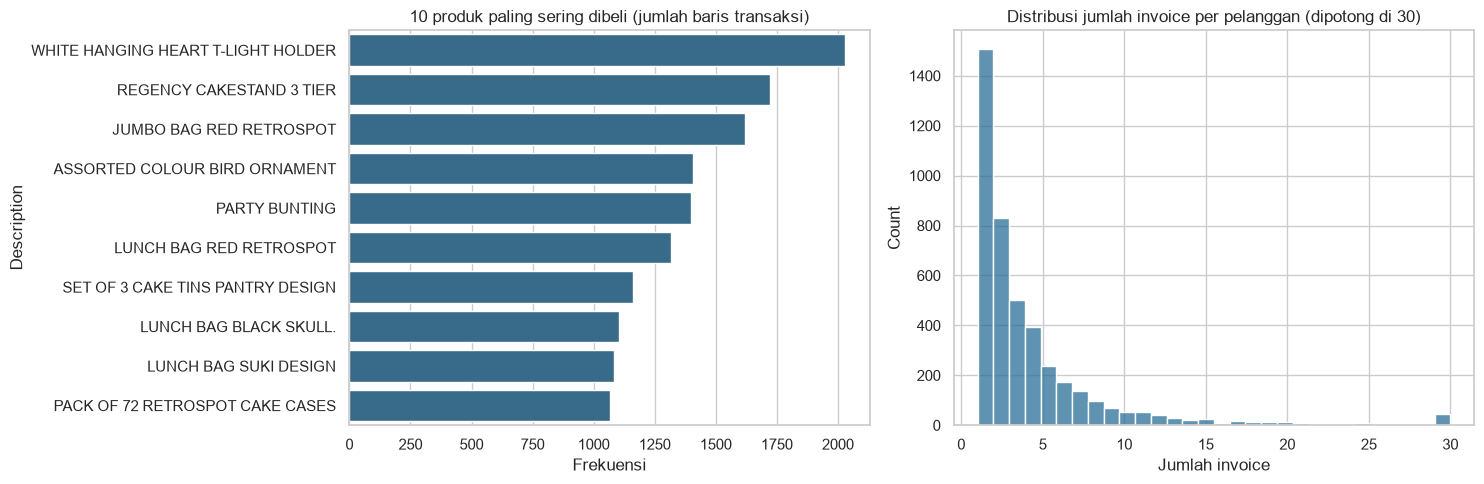

count    4335.000000
mean        4.245675
std         7.636337
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64
Pelanggan dengan >= 2 invoice: 2829 (65.3%)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

top_produk = data['Description'].value_counts().head(10)
sns.barplot(x=top_produk.values, y=top_produk.index, ax=axes[0], color='#2a6f97')
axes[0].set_title('10 produk paling sering dibeli (jumlah baris transaksi)')
axes[0].set_xlabel('Frekuensi')

inv_per_cust = data.groupby('CustomerID')['InvoiceNo'].nunique()
sns.histplot(inv_per_cust.clip(upper=30), bins=30, ax=axes[1], color='#2a6f97')
axes[1].set_title('Distribusi jumlah invoice per pelanggan (dipotong di 30)')
axes[1].set_xlabel('Jumlah invoice')
plt.tight_layout()
plt.show()

print(inv_per_cust.describe())
print(f'Pelanggan dengan >= 2 invoice: {(inv_per_cust >= 2).sum()} ({(inv_per_cust >= 2).mean():.1%})')

## 3. Persiapan Data untuk Sequential Pattern Mining

In [12]:
data = data.sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'])

# satu invoice -> satu itemset
itemset_df = (data.groupby(['CustomerID', 'InvoiceNo'], sort=False)
                  .agg(InvoiceDate=('InvoiceDate', 'min'),
                       Items=('Description', lambda s: sorted(set(s))))
                  .reset_index()
                  .sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo']))
itemset_df['JumlahItem'] = itemset_df['Items'].apply(len)
itemset_df.head()

,CustomerID,InvoiceNo,InvoiceDate,Items,JumlahItem
0,12346,541431,2011-01-18 10:01:00,[MEDIUM CERAMIC TOP STORAGE JAR],1
1,12347,537626,2010-12-07 14:57:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELI...",31
2,12347,542237,2011-01-26 14:30:00,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, AIRLINE BAG VINTAGE JET ...",29
3,12347,549222,2011-04-07 10:43:00,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE JET SET ...",24
4,12347,556201,2011-06-09 13:01:00,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE TOKYO 78, ALARM CLOCK BAKELIKE...",18


In [13]:
# satu pelanggan -> satu sequence (list of list)
seq_df = (itemset_df.groupby('CustomerID', sort=False)['Items']
                    .apply(list)
                    .reset_index(name='Sequence'))
seq_df['JumlahItemset'] = seq_df['Sequence'].apply(len)

sequences = seq_df['Sequence'].tolist()   # list of list of list
customer_ids = seq_df['CustomerID'].tolist()
N = len(sequences)

print('Jumlah sequence (pelanggan):', N)
print('Rata-rata itemset per sequence:', round(seq_df['JumlahItemset'].mean(), 2))
print('Rata-rata item per itemset   :', round(itemset_df['JumlahItem'].mean(), 2))
seq_df.head()

Jumlah sequence (pelanggan): 4335
Rata-rata itemset per sequence: 4.25
Rata-rata item per itemset   : 20.98


,CustomerID,Sequence,JumlahItemset
0,12346,[[MEDIUM CERAMIC TOP STORAGE JAR]],1
1,12347,"[[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKEL...",7
2,12348,"[[60 CAKE CASES DOLLY GIRL DESIGN, 60 CAKE CASES VINTAGE CHRISTMAS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY...",4
3,12349,"[[16 PIECE CUTLERY SET PANTRY DESIGN, 20 DOLLY PEGS RETROSPOT, BLACK/BLUE POLKADOT UMBRELLA, BROCANTE SHELF WITH HOO...",1
4,12350,"[[4 TRADITIONAL SPINNING TOPS, BATHROOM METAL SIGN, BLUE POLKADOT LUGGAGE TAG, BLUE POLKADOT PASSPORT COVER, CHOCOLA...",1


In [14]:
# contoh satu sequence pelanggan (3 itemset pertama, 5 item per itemset)
contoh = seq_df[seq_df['JumlahItemset'] >= 3].iloc[0]
print('CustomerID:', contoh['CustomerID'])
for i, its in enumerate(contoh['Sequence'][:3], 1):
    print(f'  Itemset {i} ({len(its)} item):', its[:5], '...' if len(its) > 5 else '')

CustomerID: 12347
  Itemset 1 (31 item): ['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN', 'ALARM CLOCK BAKELIKE ORANGE'] ...
  Itemset 2 (29 item): ['3D DOG PICTURE PLAYING CARDS', '60 TEATIME FAIRY CAKE CASES', '72 SWEETHEART FAIRY CAKE CASES', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET WHITE'] ...
  Itemset 3 (24 item): ['3D SHEET OF CAT STICKERS', '3D SHEET OF DOG STICKERS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'AIRLINE BAG VINTAGE JET SET RED', 'AIRLINE BAG VINTAGE JET SET WHITE'] ...


In [15]:
item2id = {it: i for i, it in enumerate(sorted(data['Description'].unique()), start=1)}
id2item = {i: it for it, i in item2id.items()}

with open('online_retail_sequences_spmf.txt', 'w') as f:
    for seq in sequences:
        baris = []
        for its in seq:
            baris += sorted(item2id[x] for x in its) + [-1]
        f.write(' '.join(map(str, baris + [-2])) + '\n')

print('Jumlah item unik:', len(item2id))
print(open('online_retail_sequences_spmf.txt').readline()[:150], '...')

Jumlah item unik: 3852
1974 -1 -2
 ...


## 4. Penerapan Algoritma PrefixSpan

### 4.1 Implementasi

In [16]:
def prefixspan(sequences, min_support, max_len=None):
    """PrefixSpan untuk sequence of itemsets.
    sequences  : list of list of list (pelanggan -> invoice -> item)
    min_support: relatif (0-1) terhadap jumlah sequence
    Return     : list of (pola_tuple, jumlah_pelanggan)
    """
    n = len(sequences)
    min_count = math.ceil(min_support * n)
    hasil = []

    def mine(prefix, projected):
        # projected: list of (id_sequence, posisi_itemset_terakhir_yang_cocok)
        hitung = defaultdict(int)
        for sid, pos in projected:
            items_setelahnya = set()
            for itemset in sequences[sid][pos + 1:]:
                items_setelahnya.update(itemset)
            for it in items_setelahnya:
                hitung[it] += 1

        for item, cnt in hitung.items():
            if cnt < min_count:
                continue
            pola = prefix + (item,)
            hasil.append((pola, cnt))
            if max_len is None or len(pola) < max_len:
                proyeksi_baru = []
                for sid, pos in projected:
                    seq = sequences[sid]
                    for j in range(pos + 1, len(seq)):
                        if item in seq[j]:            # kemunculan pertama setelah pos
                            proyeksi_baru.append((sid, j))
                            break
                mine(pola, proyeksi_baru)

    mine(tuple(), [(i, -1) for i in range(n)])
    return hasil


def hasil_ke_dataframe(hasil, n):
    sup = {p: c for p, c in hasil}
    rows = []
    for p, c in hasil:
        s = c / n
        conf = c / sup[p[:-1]] if len(p) > 1 else np.nan
        rows.append({'Pattern': ' → '.join(p), 'Length': len(p),
                     'Count': c, 'Support': s, 'Confidence': conf, 'Pattern_tuple': p})
    return (pd.DataFrame(rows)
              .sort_values(['Support', 'Confidence'], ascending=False)
              .reset_index(drop=True))

### 4.2 Percobaan minimum support awal 0.01

In [17]:
t0 = time.time()
hasil_001 = prefixspan(sequences, min_support=0.01)
print(f'min_support = 0.01 -> {len(hasil_001):,} pola ditemukan ({time.time() - t0:.1f} detik)')
print('Distribusi panjang pola:', dict(sorted(Counter(len(p) for p, _ in hasil_001).items())))

min_support = 0.01 -> 47,062 pola ditemukan (426.6 detik)
Distribusi panjang pola: {1: 1759, 2: 15686, 3: 17479, 4: 11179, 5: 949, 6: 8, 7: 2}


### 4.3 Penyesuaian minimum support

Dengan support 0.01 dihasilkan puluhan ribu pola. Jumlah ini terlalu banyak untuk dianalisis dan banyak pola panjang yang tumpang tindih. Untuk menentukan nilai yang lebih tepat, beberapa nilai minimum support dibandingkan

In [18]:
sweep = []
for ms in [0.05, 0.04, 0.03, 0.025, 0.02, 0.015, 0.01]:
    if ms == 0.01:
        h = hasil_001
    else:
        h = prefixspan(sequences, min_support=ms)
    cnt = Counter(len(p) for p, _ in h)
    sweep.append({'min_support': ms, 'min_pelanggan': math.ceil(ms * N),
                  'total_pola': len(h),
                  'pola_len_1': cnt.get(1, 0),
                  'pola_len_>=2': sum(v for k, v in cnt.items() if k >= 2),
                  'panjang_maks': max(cnt)})
sweep_df = pd.DataFrame(sweep)
sweep_df

,min_support,min_pelanggan,total_pola,pola_len_1,pola_len_>=2,panjang_maks
0,0.050,217,274,264,10,3
1,0.040,174,479,420,59,3
2,0.030,131,949,655,294,4
3,0.025,109,1494,821,673,4
4,0.020,87,3017,1044,1973,4
5,0.015,66,8023,1348,6675,5
6,0.010,44,47062,1759,45303,7


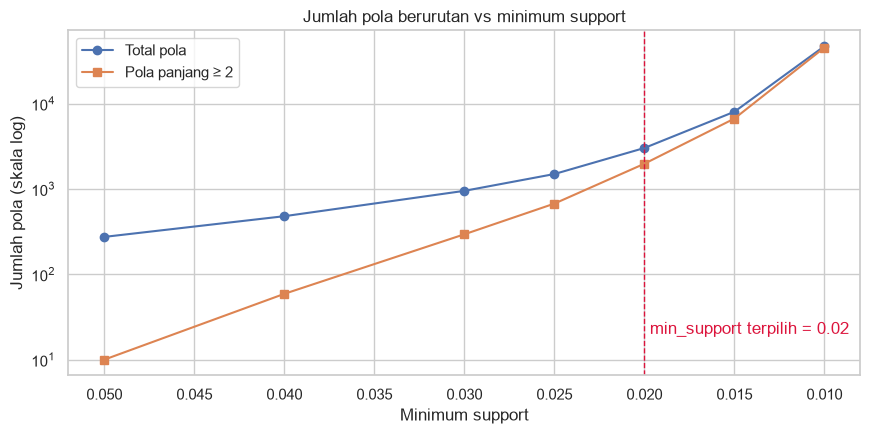

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep_df['min_support'], sweep_df['total_pola'], marker='o', label='Total pola')
ax.plot(sweep_df['min_support'], sweep_df['pola_len_>=2'], marker='s', label='Pola panjang ≥ 2')
ax.axvline(0.02, color='crimson', ls='--', lw=1)
ax.text(0.0197, 20, 'min_support terpilih = 0.02', color='crimson', ha='left')
ax.set_yscale('log')
ax.invert_xaxis()
ax.set_xlabel('Minimum support')
ax.set_ylabel('Jumlah pola (skala log)')
ax.set_title('Jumlah pola berurutan vs minimum support')
ax.legend()
plt.tight_layout()
plt.show()

`min_support = 0.02` dipilih karena nilai 0.01 menghasilkan terlalu banyak pola yang sulit diinterpretasikan, sedangkan nilai ≥ 0.04 hampir tidak menghasilkan pola berurutan sehingga 0.02 dianggap paling optimal karena menghasilkan beberapa ribu pola dengan panjang hingga 4 yang cukup representatif dan tetap dapat dianalisis

In [20]:
MIN_SUPPORT = 0.02
t0 = time.time()
hasil = prefixspan(sequences, min_support=MIN_SUPPORT)
print(f'min_support = {MIN_SUPPORT} -> {len(hasil):,} pola ({time.time() - t0:.1f} detik)')

pola_df = hasil_ke_dataframe(hasil, N)
pola_df.drop(columns='Pattern_tuple').head(10)

min_support = 0.02 -> 3,017 pola (50.0 detik)


,Pattern,Length,Count,Support,Confidence
0,REGENCY CAKESTAND 3 TIER,1,881,0.203230,NaN
1,WHITE HANGING HEART T-LIGHT HOLDER,1,856,0.197463,NaN
2,PARTY BUNTING,1,708,0.163322,NaN
3,ASSORTED COLOUR BIRD ORNAMENT,1,678,0.156401,NaN
4,SET OF 3 CAKE TINS PANTRY DESIGN,1,640,0.147636,NaN
5,PACK OF 72 RETROSPOT CAKE CASES,1,635,0.146482,NaN
6,JUMBO BAG RED RETROSPOT,1,635,0.146482,NaN
7,PAPER CHAIN KIT 50'S CHRISTMAS,1,613,0.141407,NaN
8,NATURAL SLATE HEART CHALKBOARD,1,587,0.135409,NaN
9,BAKING SET 9 PIECE RETROSPOT,1,581,0.134025,NaN


### 4.4 Validasi hasil

In [21]:
def mengandung(seq, pola):
    j = 0
    for itemset in seq:
        if j < len(pola) and pola[j] in itemset:
            j += 1
    return j == len(pola)

cek = pola_df[pola_df['Length'] >= 2].sample(20, random_state=42)
cek_bf = cek['Pattern_tuple'].apply(lambda p: sum(mengandung(s, p) for s in sequences))
print('Semua count PrefixSpan = brute force:', (cek_bf.values == cek['Count'].values).all())

Semua count PrefixSpan = brute force: True


## 5. Evaluasi Pola Berurutan

### 5.1 Daftar pola beserta support dan confidence

In [22]:
seq_pola = pola_df[pola_df['Length'] >= 2].reset_index(drop=True)
print('Jumlah pola berurutan (panjang >= 2):', len(seq_pola))
print(seq_pola['Length'].value_counts().sort_index().rename('jumlah pola'))

tampil = seq_pola[['Pattern', 'Length', 'Count', 'Support', 'Confidence']].copy()
tampil.head(20).style.format({'Support': '{:.4f}', 'Confidence': '{:.4f}'})

Jumlah pola berurutan (panjang >= 2): 1973
Length
2    1514
3     453
4       6
Name: jumlah pola, dtype: int64


,Pattern,Length,Count,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.0934,0.4731
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.0720,0.4913
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,2,291,0.0671,0.4292
4,PARTY BUNTING → PARTY BUNTING,2,280,0.0646,0.3955
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.0637,0.5188
6,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,2,229,0.0528,0.5000
7,LUNCH BAG SUKI DESIGN → LUNCH BAG SUKI DESIGN,2,226,0.0521,0.5207
8,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CAKE TINS PANTRY DESIGN,2,225,0.0519,0.3516
9,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,3,222,0.0512,0.5481


In [23]:
print('Statistik support & confidence pola berurutan:')
seq_pola[['Support', 'Confidence']].describe()

Statistik support & confidence pola berurutan:


,Support,Confidence
count,1973.000000,1973.000000
mean,0.025152,0.323175
std,0.006099,0.143861
min,0.020069,0.098751
25%,0.021223,0.211712
50%,0.023068,0.295699
75%,0.026759,0.423664
max,0.093426,0.826087


In [24]:
# simpan seluruh pola ke CSV
seq_pola.drop(columns='Pattern_tuple').to_csv('sequential_patterns_minsup_0.02.csv', index=False)

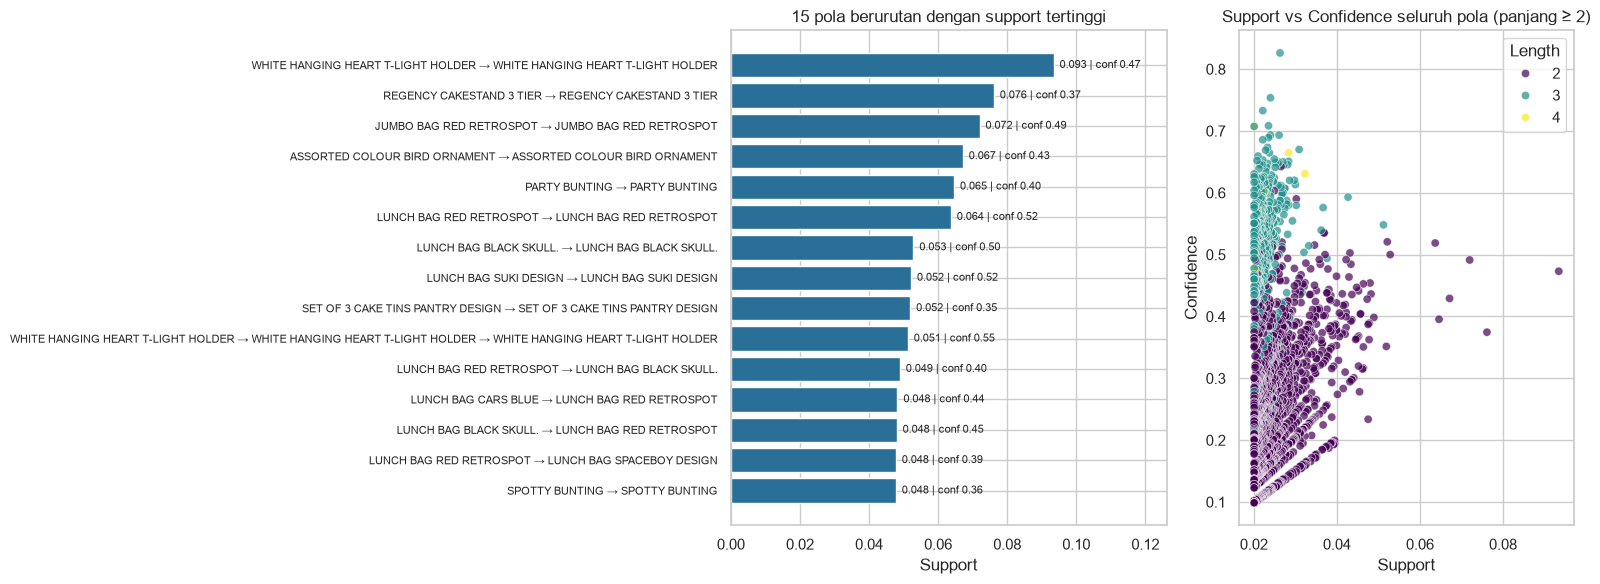

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.3, 1]})

top15 = seq_pola.head(15).iloc[::-1]
axes[0].barh(top15['Pattern'], top15['Support'], color='#2a6f97')
for y, (s, c) in enumerate(zip(top15['Support'], top15['Confidence'])):
    axes[0].text(s, y, f'  {s:.3f} | conf {c:.2f}', va='center', fontsize=8)
axes[0].set_title('15 pola berurutan dengan support tertinggi')
axes[0].set_xlabel('Support')
axes[0].tick_params(axis='y', labelsize=8)
axes[0].set_xlim(0, top15['Support'].max() * 1.35)

sns.scatterplot(data=seq_pola, x='Support', y='Confidence', hue='Length',
                palette='viridis', alpha=0.7, ax=axes[1])
axes[1].set_title('Support vs Confidence seluruh pola (panjang ≥ 2)')
plt.tight_layout()
plt.show()

### 5.2 Pola dengan confidence tertinggi

In [26]:
seq_pola.sort_values('Confidence', ascending=False)[['Pattern', 'Length', 'Count', 'Support', 'Confidence']] \
        .head(10).style.format({'Support': '{:.4f}', 'Confidence': '{:.4f}'})

,Pattern,Length,Count,Support,Confidence
523,JUMBO BAG RED RETROSPOT → JUMBO BAG DOILEY PATTERNS → JUMBO BAG RED RETROSPOT,3,114,0.0263,0.8261
805,JUMBO BAG RED RETROSPOT → JUMBO BAG DOILEY PATTERNS → JUMBO BAG VINTAGE DOILY,3,104,0.0240,0.7536
1173,LUNCH BAG RED RETROSPOT → LUNCH BAG DOILEY PATTERN → LUNCH BAG RED RETROSPOT,3,96,0.0221,0.7328
895,JUMBO BAG RED RETROSPOT → LUNCH BAG CARS BLUE → JUMBO BAG RED RETROSPOT,3,102,0.0235,0.7083
1863,JUMBO BAG RED RETROSPOT → JUMBO BAG PINK POLKADOT → JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,4,87,0.0201,0.7073
1864,JUMBO BAG RED RETROSPOT → JUMBO BAG PINK VINTAGE PAISLEY → JUMBO BAG RED RETROSPOT,3,87,0.0201,0.7073
806,JUMBO STORAGE BAG SUKI → JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,3,104,0.0240,0.6933
549,JUMBO BAG RED RETROSPOT → LUNCH BAG PINK POLKADOT → JUMBO BAG RED RETROSPOT,3,113,0.0261,0.6933
896,JUMBO BAG RED RETROSPOT → JUMBO STORAGE BAG SUKI → JUMBO BAG RED RETROSPOT,3,102,0.0235,0.6892
1174,JUMBO BAG PINK VINTAGE PAISLEY → JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,3,96,0.0221,0.6857


### 5.3 Pola pembelian berulang vs pola lintas produk

In [27]:
seq_pola['Tipe'] = np.where(seq_pola['Pattern_tuple'].apply(lambda p: len(set(p)) == 1),
                            'Repeat purchase', 'Lintas produk')
print(seq_pola['Tipe'].value_counts())

lintas = seq_pola[seq_pola['Tipe'] == 'Lintas produk']
lintas[['Pattern', 'Length', 'Count', 'Support', 'Confidence']].head(10) \
      .style.format({'Support': '{:.4f}', 'Confidence': '{:.4f}'})

Tipe
Lintas produk      1811
Repeat purchase     162
Name: count, dtype: int64


,Pattern,Length,Count,Support,Confidence
10,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,2,212,0.0489,0.3985
11,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,2,209,0.0482,0.4363
12,LUNCH BAG BLACK SKULL. → LUNCH BAG RED RETROSPOT,2,208,0.0480,0.4541
13,LUNCH BAG RED RETROSPOT → LUNCH BAG SPACEBOY DESIGN,2,207,0.0478,0.3891
15,LUNCH BAG RED RETROSPOT → LUNCH BAG SUKI DESIGN,2,206,0.0475,0.3872
16,REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS,2,206,0.0475,0.2338
18,LUNCH BAG PINK POLKADOT → LUNCH BAG RED RETROSPOT,2,201,0.0464,0.4527
20,JUMBO BAG RED RETROSPOT → JUMBO BAG VINTAGE DOILY,2,201,0.0464,0.3165
21,JUMBO BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,200,0.0461,0.3150
22,LUNCH BAG SPACEBOY DESIGN → LUNCH BAG RED RETROSPOT,2,198,0.0457,0.4041


### 5.4 Tiga pola terbaik berdasarkan support

In [28]:
top3 = seq_pola.head(3)[['Pattern', 'Count', 'Support', 'Confidence']]
top3.style.format({'Support': '{:.4f}', 'Confidence': '{:.4f}'})

,Pattern,Count,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.0934,0.4731
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.0720,0.4913


In [29]:
# detail tiga pola terbaik: support prefix (antecedent) dan jeda waktu antar pembelian
seq_dates = itemset_df.groupby('CustomerID', sort=False)['InvoiceDate'].apply(list).tolist()
sup_dict = dict(zip(pola_df['Pattern_tuple'], pola_df['Support']))

def jeda_hari(seq, dates, pola):
    """Jeda (hari) dari kemunculan pertama item awal hingga item terakhir pola."""
    j, t_awal = 0, None
    for its, t in zip(seq, dates):
        if j < len(pola) and pola[j] in its:
            if j == 0:
                t_awal = t
            j += 1
            if j == len(pola):
                return (t - t_awal).days
    return None

detail = []
for _, r in seq_pola.head(3).iterrows():
    p = r['Pattern_tuple']
    jeda = [jeda_hari(s, d, p) for s, d in zip(sequences, seq_dates)]
    jeda = [x for x in jeda if x is not None]
    detail.append({'Pattern': r['Pattern'],
                   'Support prefix': sup_dict[p[:-1]],
                   'Support pola': r['Support'],
                   'Confidence': r['Confidence'],
                   'Median jeda (hari)': np.median(jeda)})
pd.DataFrame(detail).style.format({'Support prefix': '{:.4f}', 'Support pola': '{:.4f}',
                                   'Confidence': '{:.4f}',
                                   'Median jeda (hari)': '{:.0f}'})

,Pattern,Support prefix,Support pola,Confidence,Median jeda (hari)
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,0.1975,0.0934,0.4731,75
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,0.2032,0.0761,0.3746,73
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,0.1465,0.0720,0.4913,88


**Interpretasi tiga pola terbaik**

1. **WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER**
   (support 0.0934, confidence 0.473): sebanyak 405 pelanggan (9,3%) membeli tempat lilin ini lalu membelinya lagi di transaksi berikutnya. Dari pelanggan yang pernah membeli produk ini, 47% kembali membelinya, dengan median jeda sekitar 75 hari. Produk ini best-seller yang dibeli ulang secara rutin. Banyak pelanggan toko ini adalah pedagang grosir yang menjual kembali, sehingga stok produk ini perlu dijaga dan pengingat re-order bisa dikirim sekitar 2–3 bulan setelah pembelian pertama.

2. **REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER**
   (support 0.0761, confidence 0.375): 330 pelanggan (7,6%) membeli ulang cake stand ini dengan median jeda sekitar 73 hari. Ini adalah produk dengan jumlah pembeli terbanyak (20% pelanggan), dan lebih dari sepertiga pembelinya kembali membeli. Produk ini cocok dijadikan anchor product untuk promosi, misalnya dengan menawarkan produk seri Regency lain. Pola lintas produk **REGENCY CAKESTAND 3 TIER → SET OF 3 REGENCY CAKE TINS** (support 0.0475) juga ditemukan.

3. **JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT**
   (support 0.0720, confidence 0.491): 312 pelanggan (7,2%) membeli ulang tas jumbo ini dengan median jeda sekitar 88 hari. Confidence-nya paling tinggi di antara ketiga pola, karena hampir separuh pembelinya kembali membeli. Tas ini bersifat consumable bagi pedagang, sehingga cocok untuk program langganan atau diskon pembelian ulang.